# GUIDE and CART regression trees on the diabetes data

This notebook compares `GuideRegressor` with scikit-learn's `DecisionTreeRegressor` (CART) on the diabetes dataset bundled with scikit-learn: ten baseline variables for 442 patients and a measure of disease progression one year later.

Besides piecewise-constant trees like CART's, GUIDE can fit a linear model in each leaf, which often gives a smaller tree with similar accuracy, and it can fit quantile trees.

In [1]:
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from sklearn.datasets import load_diabetes
from sklearn.ensemble import RandomForestRegressor
from sklearn.model_selection import GridSearchCV, KFold, cross_validate, train_test_split
from sklearn.tree import DecisionTreeRegressor
from sklearn.tree import plot_tree as plot_cart

from guide import GuideForestRegressor, GuideRegressor, plot_tree

X, y = load_diabetes(return_X_y=True, as_frame=True)
X.head()

,age,sex,bmi,bp,s1,s2,s3,s4,s5,s6
0,0.038076,0.050680,0.061696,0.021872,-0.044223,-0.034821,-0.043401,-0.002592,0.019907,-0.017646
1,-0.001882,-0.044642,-0.051474,-0.026328,-0.008449,-0.019163,0.074412,-0.039493,-0.068332,-0.092204
2,0.085299,0.050680,0.044451,-0.005670,-0.045599,-0.034194,-0.032356,-0.002592,0.002861,-0.025930
3,-0.089063,-0.044642,-0.011595,-0.036656,0.012191,0.024991,-0.036038,0.034309,0.022688,-0.009362
4,0.005383,-0.044642,-0.036385,0.021872,0.003935,0.015596,0.008142,-0.002592,-0.031988,-0.046641


## Piecewise-constant trees

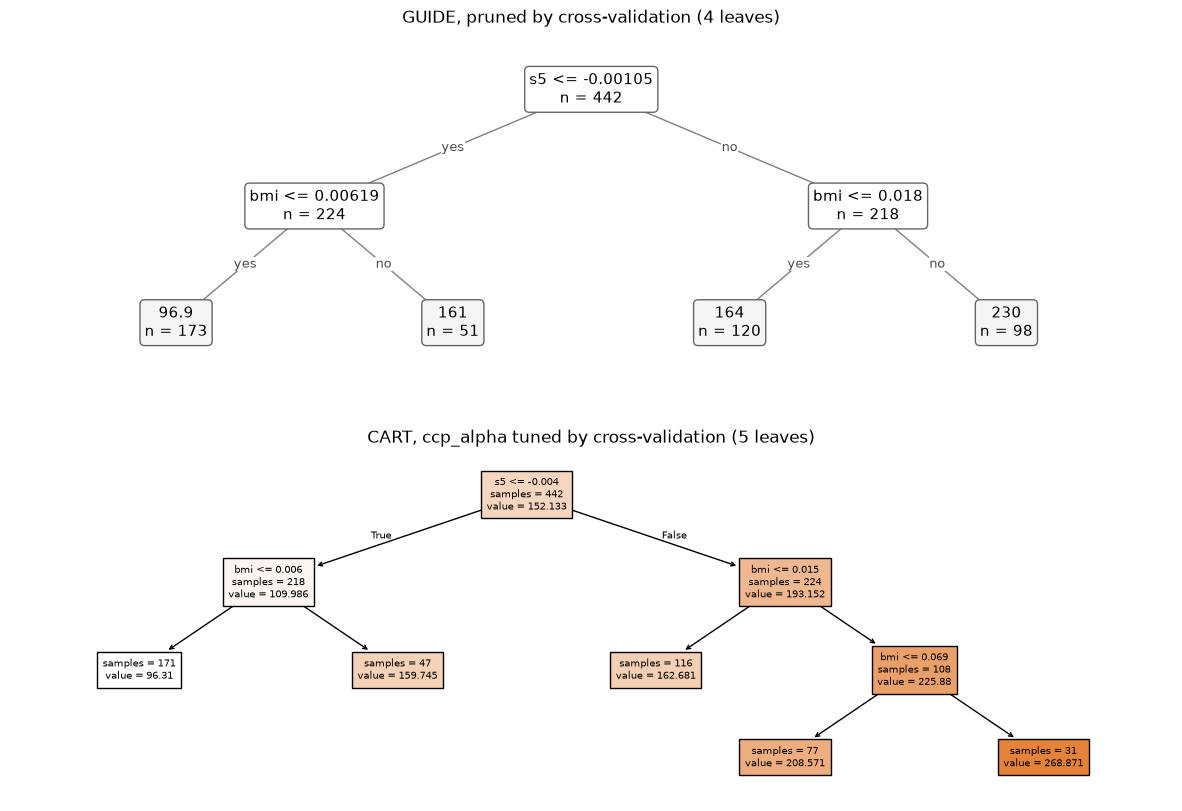

In [2]:
guide = GuideRegressor().fit(X, y)
cart = GridSearchCV(DecisionTreeRegressor(random_state=0),
                    {"ccp_alpha": np.r_[0, np.logspace(0, 3, 13)]}, cv=5).fit(X, y)

fig, axes = plt.subplots(2, 1, figsize=(15, 10))
plot_tree(guide, ax=axes[0])
axes[0].set_title(f"GUIDE, pruned by cross-validation ({guide.get_n_leaves()} leaves)")
plot_cart(cart.best_estimator_, feature_names=list(X.columns), filled=True, impurity=False,
          fontsize=7, ax=axes[1])
axes[1].set_title(f"CART, ccp_alpha tuned by cross-validation "
                  f"({cart.best_estimator_.get_n_leaves()} leaves)")
plt.show()

## Linear leaves

With `node_model="linear"`, each leaf fits a least-squares regression. `feature_roles` controls which variables split and which enter the leaf models; by default every numeric variable can do both.

On these data, cross-validation prunes the linear-leaf tree back to its root: progression is close to linear in the predictors, so a single multiple regression beats any split.

In [3]:
linear = GuideRegressor(node_model="linear").fit(X, y)
print(f"leaves after pruning: {linear.get_n_leaves()}")

leaves after pruning: 1


Roles also allow simpler models that are easy to plot. Below, `bmi` is the only regressor in each leaf and the remaining variables only split, giving a piecewise simple linear regression on `bmi`. `plot_tree` shows each leaf's fitted line:

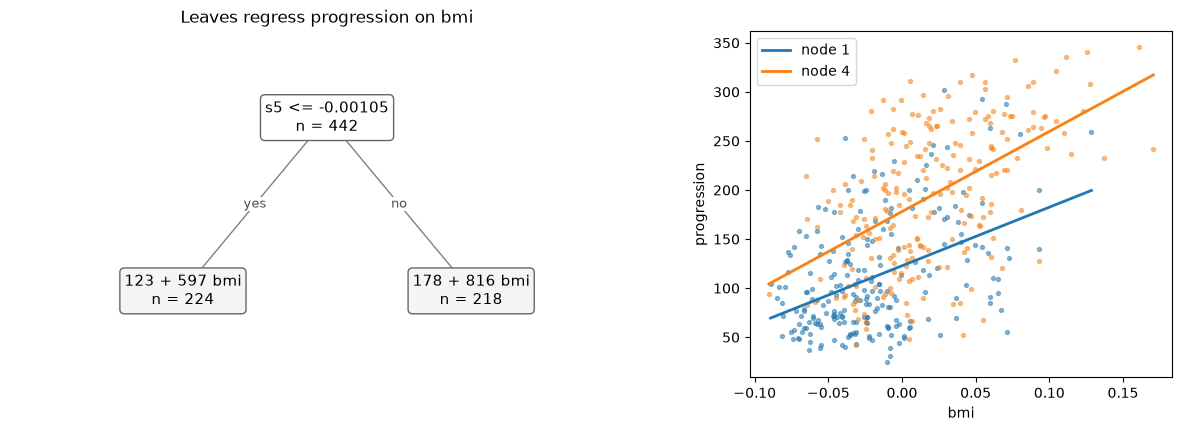

In [4]:
roles = {name: "split" for name in X.columns} | {"bmi": "fit"}
simple = GuideRegressor(node_model="linear", feature_roles=roles, max_depth=2).fit(X, y)

fig, axes = plt.subplots(1, 2, figsize=(15, 4.5), gridspec_kw={"width_ratios": [3, 2]})
plot_tree(simple, ax=axes[0])
axes[0].set_title("Leaves regress progression on bmi")
leaf = simple.apply(X)
for i, node in enumerate(np.unique(leaf)):
    rows = leaf == node
    axes[1].scatter(X.bmi[rows], y[rows], s=8, alpha=0.5, color=f"C{i}")
    order = np.argsort(X.bmi[rows].to_numpy())
    axes[1].plot(X.bmi[rows].to_numpy()[order], simple.predict(X[rows])[order], color=f"C{i}",
                 lw=2, label=f"node {node}")
axes[1].set(xlabel="bmi", ylabel="progression")
axes[1].legend()
plt.show()

## Accuracy and tree size

Ten-fold cross-validated R², mean leaves and mean fit time. The tuned CART chooses `ccp_alpha` by an inner 5-fold grid search.

In [5]:
def leaves(model):
    model = getattr(model, "best_estimator_", model)
    return model.get_n_leaves() if hasattr(model, "get_n_leaves") else np.nan


def compare(models, X, y, cv, scoring=None):
    rows = []
    for name, model in models.items():
        result = cross_validate(model, X, y, cv=cv, scoring=scoring, return_estimator=True)
        rows.append({
            "model": name,
            "score": result["test_score"].mean(),
            "sd": result["test_score"].std(),
            "leaves": np.mean([leaves(e) for e in result["estimator"]]),
            "fit seconds": result["fit_time"].mean(),
        })
    return pd.DataFrame(rows).set_index("model").round(3)


models = {
    "GUIDE, constant leaves": GuideRegressor(),
    "GUIDE, linear leaves": GuideRegressor(node_model="linear"),
    "CART, defaults": DecisionTreeRegressor(random_state=0),
    "CART, tuned": GridSearchCV(DecisionTreeRegressor(random_state=0),
                                {"ccp_alpha": np.r_[0, np.logspace(0, 3, 13)]}, cv=5),
    "GUIDE forest": GuideForestRegressor(n_estimators=100),
    "random forest": RandomForestRegressor(n_estimators=100, n_jobs=-1, random_state=0),
}
compare(models, X, y, KFold(10, shuffle=True, random_state=0))

,score,sd,leaves,fit seconds
model,,,,
"GUIDE, constant leaves",0.342,0.177,5.5,0.011
"GUIDE, linear leaves",0.477,0.114,1.1,0.230
"CART, defaults",-0.209,0.228,388.6,0.001
"CART, tuned",0.335,0.136,5.1,0.132
GUIDE forest,0.456,0.101,NaN,0.052
random forest,0.417,0.128,NaN,0.042


The single linear model (GUIDE with linear leaves, pruned to one node) is the most accurate, ahead of both forests. Among piecewise-constant trees, GUIDE and tuned CART are close, while the unpruned CART tree overfits badly (negative R²).

## Quantile trees

`loss="quantile"` fits a tree to a conditional quantile. Trees for the 10% and 90% quantiles give an 80% prediction interval; its coverage on held-out data should be near 80%. (scikit-learn's `DecisionTreeRegressor` has no quantile criterion.)

In [6]:
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.3, random_state=0)
lower = GuideRegressor(loss="quantile", quantile=0.1).fit(X_train, y_train)
upper = GuideRegressor(loss="quantile", quantile=0.9).fit(X_train, y_train)
lo, hi = lower.predict(X_test), upper.predict(X_test)
print(f"coverage: {np.mean((y_test >= lo) & (y_test <= hi)):.2f}, "
      f"mean width: {np.mean(hi - lo):.0f}")

coverage: 0.78, mean width: 164
